**Import libraries**

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


**Load Datasets**

In [16]:
df=pd.read_csv("../data/GlobalWeatherRepository.csv")
df


,country,location_name,latitude,longitude,timezone,last_updated_epoch,last_updated,temperature_celsius,temperature_fahrenheit,condition_text
0,Afghanistan,Kabul,34.5200,69.1800,Asia/Kabul,1715849100,2024-05-16 13:15,26.6,79.8,Partly Cloudy
1,Albania,Tirana,41.3300,19.8200,Europe/Tirane,1715849100,2024-05-16 10:45,19.0,66.2,Partly cloudy
2,Algeria,Algiers,36.7600,3.0500,Africa/Algiers,1715849100,2024-05-16 09:45,23.0,73.4,Sunny
3,Andorra,Andorra La Vella,42.5000,1.5200,Europe/Andorra,1715849100,2024-05-16 10:45,6.3,43.3,Light drizzle
4,Angola,Luanda,-8.8400,13.2300,Africa/Luanda,1715849100,2024-05-16 09:45,26.0,78.8,Partly cloudy
...,...,...,...,...,...,...,...,...,...,...
170923,Venezuela,Caracas,10.5000,-66.9167,America/Caracas,1791869400,2026-10-13 01:30,18.5,65.4,Patchy rain nearby
170924,Vietnam,Hanoi,21.0333,105.8500,Asia/Bangkok,1791869400,2026-10-13 12:30,32.8,91.0,Partly Cloudy
170925,Yemen,Sanaa,15.3547,44.2067,Asia/Aden,1791869400,2026-10-13 08:30,17.6,63.7,Overcast
170926,Zambia,Lusaka,-15.4167,28.2833,Africa/Lusaka,1791869400,2026-10-13 07:30,22.0,71.7,Sunny


In [17]:
df.head()

,country,location_name,latitude,longitude,timezone,last_updated_epoch,last_updated,temperature_celsius,temperature_fahrenheit,condition_text
0,Afghanistan,Kabul,34.52,69.18,Asia/Kabul,1715849100,2024-05-16 13:15,26.6,79.8,Partly Cloudy
1,Albania,Tirana,41.33,19.82,Europe/Tirane,1715849100,2024-05-16 10:45,19.0,66.2,Partly cloudy
2,Algeria,Algiers,36.76,3.05,Africa/Algiers,1715849100,2024-05-16 09:45,23.0,73.4,Sunny
3,Andorra,Andorra La Vella,42.50,1.52,Europe/Andorra,1715849100,2024-05-16 10:45,6.3,43.3,Light drizzle
4,Angola,Luanda,-8.84,13.23,Africa/Luanda,1715849100,2024-05-16 09:45,26.0,78.8,Partly cloudy


In [18]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column names
print("\nDataset Columns:")
print(df.columns.tolist())

# Dataset information
print("\nDataset Information:")
df.info()

Dataset Shape: (170928, 10)

Dataset Columns:
['country', 'location_name', 'latitude', 'longitude', 'timezone', 'last_updated_epoch', 'last_updated', 'temperature_celsius', 'temperature_fahrenheit', 'condition_text']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 170928 entries, 0 to 170927
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   country                 170928 non-null  str    
 1   location_name           170928 non-null  str    
 2   latitude                170928 non-null  float64
 3   longitude               170928 non-null  float64
 4   timezone                170928 non-null  str    
 5   last_updated_epoch      170928 non-null  int64  
 6   last_updated            170928 non-null  str    
 7   temperature_celsius     170928 non-null  float64
 8   temperature_fahrenheit  170928 non-null  float64
 9   condition_text          170928 non-null  str    
dtypes: float

In [19]:
# Missing values
print("Missing Values:")
print(df.isnull().sum().sort_values(ascending=False))

# Duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

Missing Values:
country                   0
location_name             0
latitude                  0
longitude                 0
timezone                  0
last_updated_epoch        0
last_updated              0
temperature_celsius       0
temperature_fahrenheit    0
condition_text            0
dtype: int64

Duplicate Records: 1


In [21]:
# Check dataset size before cleaning
print("Before cleaning:", df.shape)

# Remove duplicate records
df.drop_duplicates(inplace=True)

# Reset index
df.reset_index(drop=True, inplace=True)

# Verify duplicates
print("After cleaning:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

Before cleaning: (170928, 10)


C:\Users\rohit\AppData\Local\Temp\ipykernel_7296\414663652.py:5: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)
C:\Users\rohit\AppData\Local\Temp\ipykernel_7296\414663652.py:8: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.reset_index(drop=True, inplace=True)


After cleaning: (170927, 10)
Remaining duplicates: 0


In [25]:
# Separate numerical and categorical columns

numerical_columns = df.select_dtypes(include=np.number).columns.tolist()

categorical_columns = df.select_dtypes(include="object").columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)

print("\nTotal Numerical Columns:", len(numerical_columns))
print("Total Categorical Columns:", len(categorical_columns))

Numerical Columns:
['latitude', 'longitude', 'last_updated_epoch', 'temperature_celsius', 'temperature_fahrenheit']

Categorical Columns:
['country', 'location_name', 'timezone', 'last_updated', 'condition_text']

Total Numerical Columns: 5
Total Categorical Columns: 5


C:\Users\rohit\AppData\Local\Temp\ipykernel_7296\3007826331.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include="object").columns.tolist()


In [26]:
# Convert last_updated into datetime format
df["last_updated"] = pd.to_datetime(df["last_updated"], errors="coerce")

# Verify conversion
print("Data type:", df["last_updated"].dtype)

print("\nDate Range:")
print("Start Date:", df["last_updated"].min())
print("End Date:", df["last_updated"].max())

print("\nSample Dates:")
print(df["last_updated"].head())

Data type: datetime64[us]

Date Range:
Start Date: 2024-05-16 01:45:00
End Date: 2026-10-13 18:45:00

Sample Dates:
0   2024-05-16 13:15:00
1   2024-05-16 10:45:00
2   2024-05-16 09:45:00
3   2024-05-16 10:45:00
4   2024-05-16 09:45:00
Name: last_updated, dtype: datetime64[us]


In [27]:
# Select weather-related numerical features
weather_features = [
    "temperature_celsius"
]

# Calculate IQR and detect outliers
outlier_summary = []

for col in weather_features:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_summary.append({
        "Feature": col,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier Percentage": round(
            len(outliers) / len(df) * 100, 2
        )
    })

outlier_df = pd.DataFrame(outlier_summary)

outlier_df

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,temperature_celsius,-1.05,44.95,3125,1.83


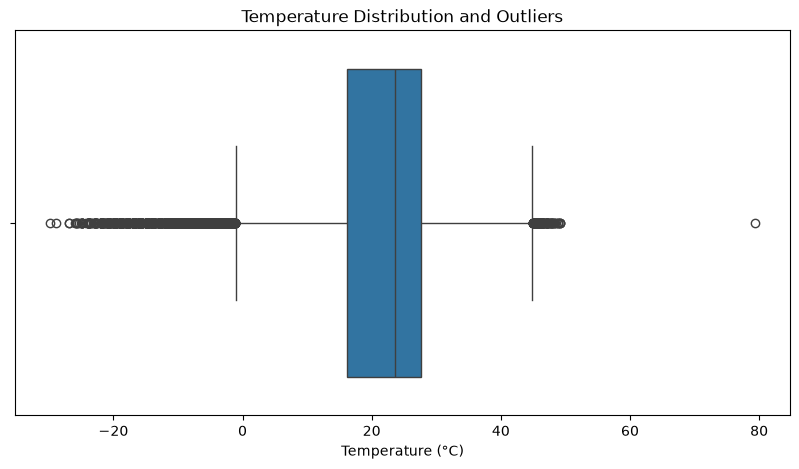

In [28]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["temperature_celsius"])

plt.title("Temperature Distribution and Outliers")
plt.xlabel("Temperature (°C)")

plt.show()

In [29]:
# Check temperature statistics
print("Temperature Statistics:")
print(df["temperature_celsius"].describe())

# Display lowest 10 temperature records
print("\nLowest 10 Temperatures:")
display(
    df.nsmallest(10, "temperature_celsius")[
        ["country", "location_name", "temperature_celsius",
         "temperature_fahrenheit", "last_updated"]
    ]
)

# Display highest 10 temperature records
print("\nHighest 10 Temperatures:")
display(
    df.nlargest(10, "temperature_celsius")[
        ["country", "location_name", "temperature_celsius",
         "temperature_fahrenheit", "last_updated"]
    ]
)

Temperature Statistics:
count    170927.000000
mean         21.445197
std           9.271732
min         -29.800000
25%          16.200000
50%          23.600000
75%          27.700000
max          79.300000
Name: temperature_celsius, dtype: float64

Lowest 10 Temperatures:


,country,location_name,temperature_celsius,temperature_fahrenheit,last_updated
118990,Mongolia,Ulaanbaatar,-29.8,-21.6,2026-01-18 15:00:00
119182,Mongolia,Ulaanbaatar,-28.9,-20.0,2026-01-20 15:15:00
121617,Belarus,Minsk,-26.9,-16.4,2026-02-02 10:00:00
118606,Mongolia,Ulaanbaatar,-26.8,-16.2,2026-01-16 15:15:00
118801,Mongolia,Ulaanbaatar,-25.9,-14.6,2026-01-17 15:00:00
115680,Russia,Chi-Chi-Erh,-25.8,-14.4,2026-01-01 14:15:00
118507,Belarus,Minsk,-25.8,-14.4,2026-01-16 10:15:00
118774,Kazakhstan,Astana,-25.7,-14.3,2026-01-17 12:00:00
119376,Mongolia,Ulaanbaatar,-25.7,-14.3,2026-01-21 15:00:00
159699,Iceland,Abaer,-25.4,-13.7,2026-08-17 06:00:00



Highest 10 Temperatures:


,country,location_name,temperature_celsius,temperature_fahrenheit,last_updated
137275,Fiji Islands,Suva,79.3,174.7,2026-04-24 18:30:00
6896,Kuwait,Kuwait City,49.2,120.6,2024-06-19 16:45:00
7460,Iraq,Baghdad,49.1,120.4,2024-06-22 16:45:00
11145,Iraq,Baghdad,49.1,120.3,2024-07-11 15:45:00
8425,Kuwait,Kuwait City,48.9,120.0,2024-06-27 16:15:00
11338,Iraq,Baghdad,48.8,119.8,2024-07-12 15:45:00
85049,Kuwait,Kuwait City,48.8,119.8,2025-07-28 11:30:00
76862,Kuwait,Kuwait City,48.6,119.5,2025-06-16 12:00:00
7270,Iraq,Baghdad,48.4,119.1,2024-06-21 16:30:00
9975,Iraq,Baghdad,48.3,118.9,2024-07-05 15:45:00


In [30]:
# Calculate expected Fahrenheit values
expected_fahrenheit = (
    df["temperature_celsius"] * 9/5
) + 32

# Calculate conversion difference
df["temperature_check"] = abs(
    df["temperature_fahrenheit"] - expected_fahrenheit
)

# Identify inconsistent records
inconsistent_records = df[
    df["temperature_check"] > 0.2
]

print("Inconsistent Temperature Records:",
      len(inconsistent_records))

# Display suspicious extreme temperatures
suspicious_records = df[
    df["temperature_celsius"] > 60
]

display(
    suspicious_records[
        [
            "country",
            "location_name",
            "temperature_celsius",
            "temperature_fahrenheit",
            "last_updated"
        ]
    ]
)

Inconsistent Temperature Records: 0


,country,location_name,temperature_celsius,temperature_fahrenheit,last_updated
137275,Fiji Islands,Suva,79.3,174.7,2026-04-24 18:30:00


In [31]:
# Investigate Suva temperature observations
suva_data = df[
    df["location_name"] == "Suva"
].sort_values("last_updated")

print("Total Suva Records:", len(suva_data))

# Display observations around the suspicious date
suspicious_date = pd.Timestamp("2026-04-24")

nearby_records = suva_data[
    (suva_data["last_updated"] >= suspicious_date - pd.Timedelta(days=3)) &
    (suva_data["last_updated"] <= suspicious_date + pd.Timedelta(days=3))
]

display(
    nearby_records[
        [
            "country",
            "location_name",
            "temperature_celsius",
            "temperature_fahrenheit",
            "last_updated"
        ]
    ]
)

Total Suva Records: 878


,country,location_name,temperature_celsius,temperature_fahrenheit,last_updated
136690,Fiji Islands,Suva,26.3,79.3,2026-04-21 18:45:00
136885,Fiji Islands,Suva,26.2,79.2,2026-04-22 18:30:00
137080,Fiji Islands,Suva,26.4,79.5,2026-04-23 18:30:00
137275,Fiji Islands,Suva,79.3,174.7,2026-04-24 18:30:00
137470,Fiji Islands,Suva,25.4,77.7,2026-04-25 18:30:00
137665,Fiji Islands,Suva,27.1,80.8,2026-04-26 18:30:00


In [32]:
# Sort records by city and date
df = df.sort_values(
    ["location_name", "last_updated"]
).copy()

# Identify invalid temperature values
invalid_mask = df["temperature_celsius"] > 60

print("Invalid Temperature Records:", invalid_mask.sum())

# Replace invalid values with NaN
df.loc[invalid_mask, "temperature_celsius"] = np.nan

# Interpolate using observations from the same city
df["temperature_celsius"] = (
    df.groupby("location_name")["temperature_celsius"]
    .transform(lambda x: x.interpolate(limit_direction="both"))
)

# Recalculate Fahrenheit
df["temperature_fahrenheit"] = (
    df["temperature_celsius"] * 9/5
) + 32

# Verify correction
print("\nCorrected Suva Observation:")

display(
    df[
        (df["location_name"] == "Suva") &
        (df["last_updated"].dt.date == pd.Timestamp("2026-04-24").date())
    ][
        ["location_name", "temperature_celsius",
         "temperature_fahrenheit", "last_updated"]
    ]
)

Invalid Temperature Records: 1

Corrected Suva Observation:


,location_name,temperature_celsius,temperature_fahrenheit,last_updated
137275,Suva,25.9,78.62,2026-04-24 18:30:00


In [33]:
# Check missing values after cleaning
print("Total Missing Values:",
      df.isnull().sum().sum())

# Check duplicate records
print("Duplicate Records:",
      df.duplicated().sum())

# Check invalid temperature values
print("Temperatures Above 60°C:",
      (df["temperature_celsius"] > 60).sum())

# Updated temperature statistics
print("\nUpdated Temperature Statistics:")
print(df["temperature_celsius"].describe())

Total Missing Values: 0
Duplicate Records: 0
Temperatures Above 60°C: 0

Updated Temperature Statistics:
count    170927.000000
mean         21.444885
std           9.270682
min         -29.800000
25%          16.200000
50%          23.600000
75%          27.700000
max          49.200000
Name: temperature_celsius, dtype: float64


In [34]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Select numerical features for scaling
scaling_features = [
    "latitude",
    "longitude",
    "temperature_celsius"
]

# Standard Scaling
standard_scaler = StandardScaler()

df_standard_scaled = df.copy()

df_standard_scaled[scaling_features] = standard_scaler.fit_transform(
    df[scaling_features]
)

# Min-Max Scaling
minmax_scaler = MinMaxScaler()

df_minmax_scaled = df.copy()

df_minmax_scaled[scaling_features] = minmax_scaler.fit_transform(
    df[scaling_features]
)

print("Standard Scaling Completed!")
print("Min-Max Scaling Completed!")

Standard Scaling Completed!
Min-Max Scaling Completed!


In [35]:
print("Standard Scaled Data:")
display(df_standard_scaled[scaling_features].describe().round(3))

print("\nMin-Max Scaled Data:")
display(df_minmax_scaled[scaling_features].describe().round(3))

Standard Scaled Data:


,latitude,longitude,temperature_celsius
count,170927.000,170927.000,170927.000
mean,0.000,-0.000,0.000
std,1.000,1.000,1.000
min,-2.486,-2.996,-5.528
25%,-0.625,-0.435,-0.566
50%,-0.083,-0.006,0.232
75%,0.866,0.427,0.675
max,1.888,2.394,2.994



Min-Max Scaled Data:


,latitude,longitude,temperature_celsius
count,170927.000,170927.000,170927.000
mean,0.568,0.556,0.649
std,0.229,0.186,0.117
min,0.000,0.000,0.000
25%,0.425,0.475,0.582
50%,0.549,0.555,0.676
75%,0.766,0.635,0.728
max,1.000,1.000,1.000


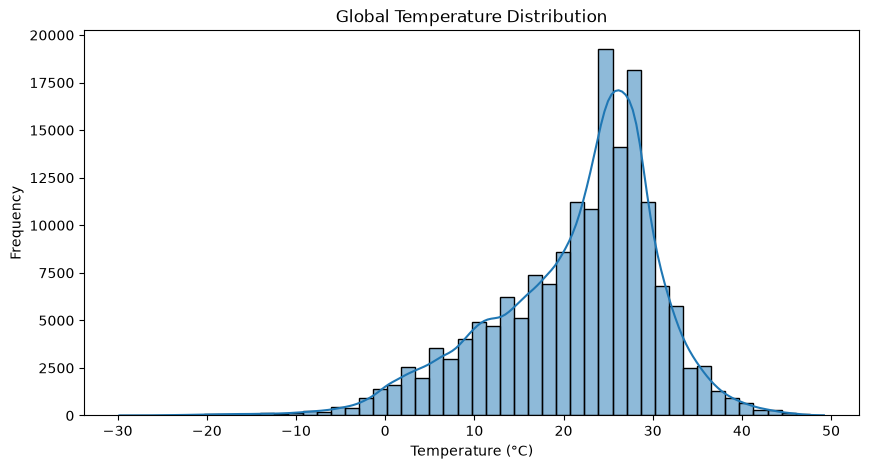

In [36]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["temperature_celsius"],
    bins=50,
    kde=True
)

plt.title("Global Temperature Distribution")
plt.xlabel("Temperature (°C)")
plt.ylabel("Frequency")
plt.show()

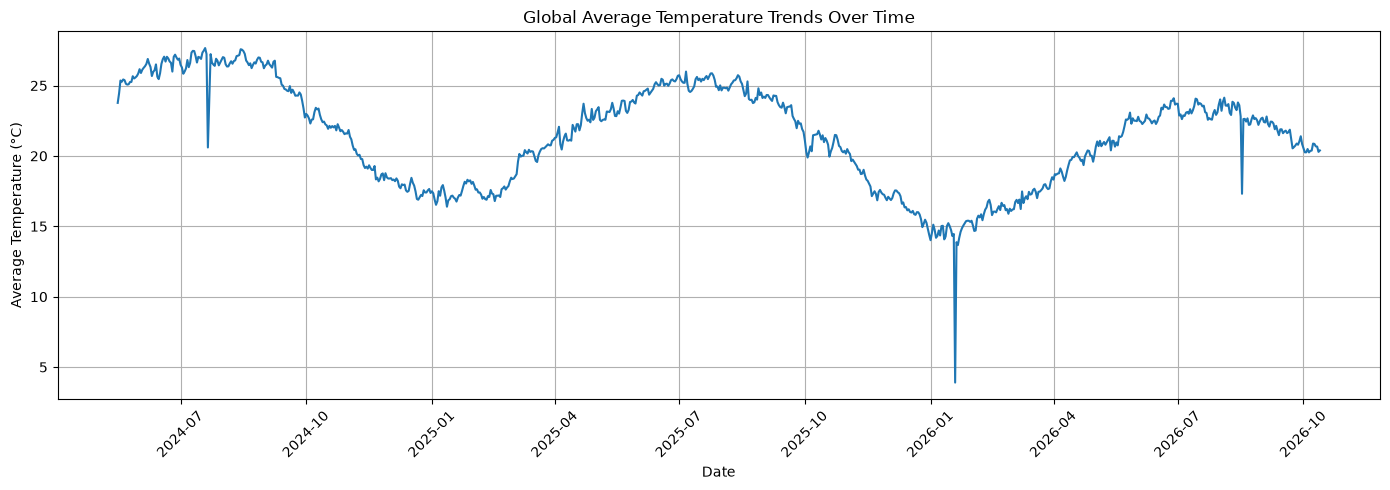

In [39]:
daily_temperature = (
    df.groupby(df["last_updated"].dt.date)["temperature_celsius"]
    .mean()
    .reset_index()
)

daily_temperature.columns = ["date", "average_temperature"]

plt.figure(figsize=(14, 5))

plt.plot(
    daily_temperature["date"],
    daily_temperature["average_temperature"]
)

plt.title("Global Average Temperature Trends Over Time")
plt.xlabel("Date")
plt.ylabel("Average Temperature (°C)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

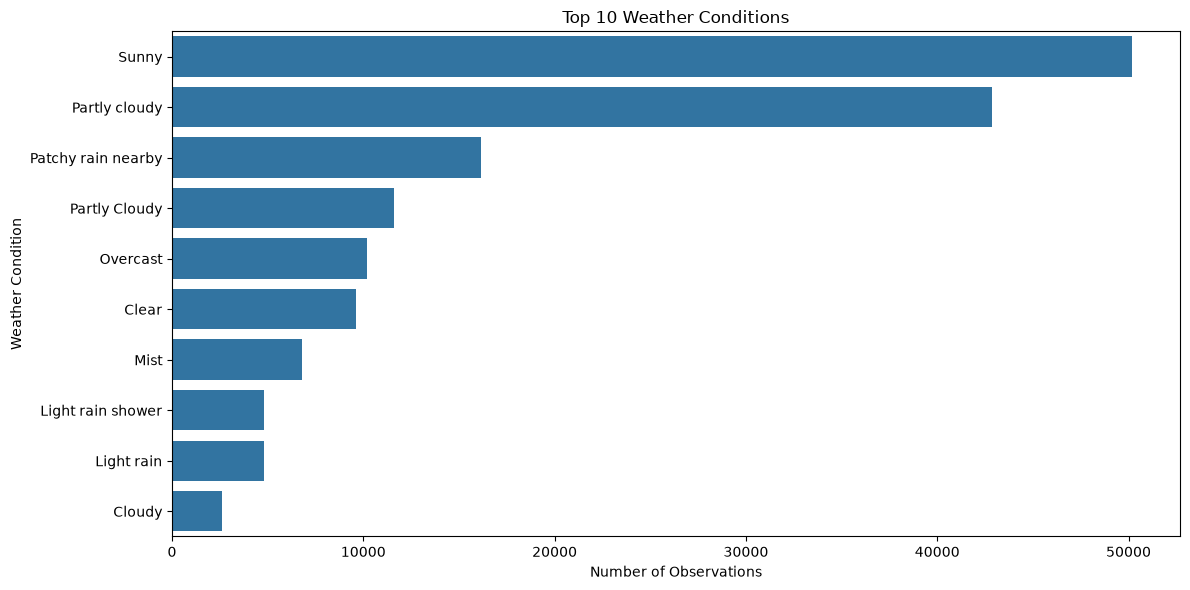

In [40]:
# Count weather conditions
weather_counts = df["condition_text"].value_counts().head(10)

# Visualize weather conditions
plt.figure(figsize=(12, 6))

sns.barplot(
    x=weather_counts.values,
    y=weather_counts.index
)

plt.title("Top 10 Weather Conditions")
plt.xlabel("Number of Observations")
plt.ylabel("Weather Condition")
plt.tight_layout()
plt.show()

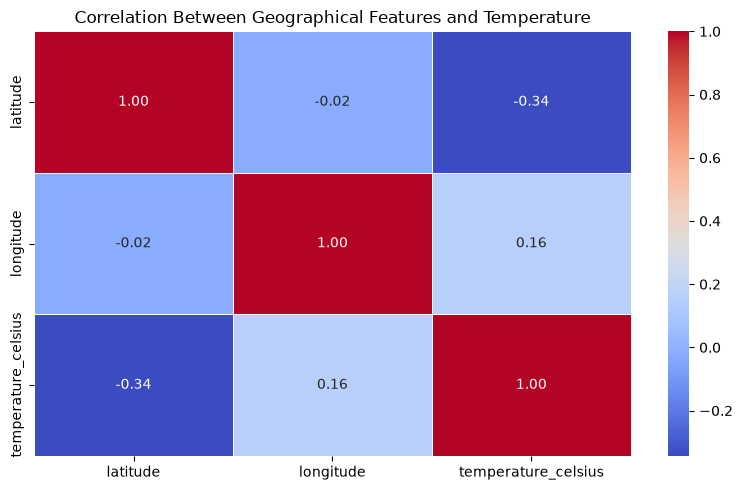

In [41]:
# Select numerical features
correlation_data = df[
    ["latitude", "longitude", "temperature_celsius"]
]

# Calculate correlation matrix
correlation_matrix = correlation_data.corr()

# Visualize correlation
plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Geographical Features and Temperature")
plt.tight_layout()
plt.show()

**Advanced EDA**

In [43]:
from sklearn.ensemble import IsolationForest

# Prepare temperature data
anomaly_data = df[["temperature_celsius"]].copy()

# Initialize Isolation Forest
iso_forest = IsolationForest(
    contamination=0.02,
    random_state=42
)

# Detect anomalies
df["anomaly"] = iso_forest.fit_predict(anomaly_data)

# Assign labels
df["anomaly_label"] = df["anomaly"].map({
    1: "Normal",
    -1: "Anomaly"
})

# Display results
print("Anomaly Detection Results:")
print(df["anomaly_label"].value_counts())

print("\nAnomaly Percentage:")
print(
    (df["anomaly_label"].value_counts(normalize=True) * 100).round(2)
)

Anomaly Detection Results:
anomaly_label
Normal     167596
Anomaly      3331
Name: count, dtype: int64

Anomaly Percentage:
anomaly_label
Normal     98.05
Anomaly     1.95
Name: proportion, dtype: float64


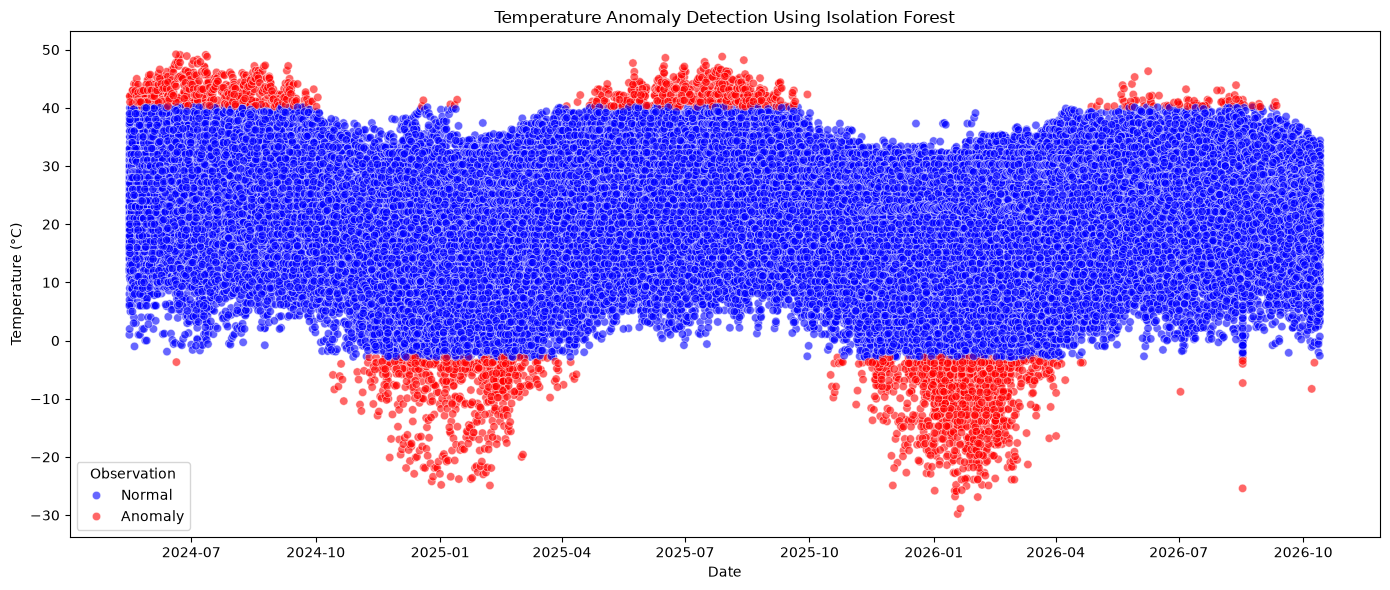

In [44]:
plt.figure(figsize=(14, 6))

sns.scatterplot(
    data=df,
    x="last_updated",
    y="temperature_celsius",
    hue="anomaly_label",
    palette={
        "Normal": "blue",
        "Anomaly": "red"
    },
    alpha=0.6
)

plt.title("Temperature Anomaly Detection Using Isolation Forest")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend(title="Observation")
plt.tight_layout()
plt.show()

In [45]:
# Extract anomalous observations
anomalies = df[df["anomaly_label"] == "Anomaly"].copy()

print("Total Anomalies Detected:", len(anomalies))

print("\nAnomalous Temperature Statistics:")
display(anomalies["temperature_celsius"].describe().round(2))

print("\nTop 10 Lowest Anomalous Temperatures:")
display(
    anomalies[
        ["country", "location_name", "last_updated", "temperature_celsius"]
    ]
    .sort_values("temperature_celsius")
    .head(10)
)

print("\nTop 10 Highest Anomalous Temperatures:")
display(
    anomalies[
        ["country", "location_name", "last_updated", "temperature_celsius"]
    ]
    .sort_values("temperature_celsius", ascending=False)
    .head(10)
)

Total Anomalies Detected: 3331

Anomalous Temperature Statistics:


count    3331.00
mean       10.34
std        25.20
min       -29.80
25%        -8.60
50%        -4.00
75%        41.20
max        49.20
Name: temperature_celsius, dtype: float64


Top 10 Lowest Anomalous Temperatures:


,country,location_name,last_updated,temperature_celsius
118990,Mongolia,Ulaanbaatar,2026-01-18 15:00:00,-29.8
119182,Mongolia,Ulaanbaatar,2026-01-20 15:15:00,-28.9
121617,Belarus,Minsk,2026-02-02 10:00:00,-26.9
118606,Mongolia,Ulaanbaatar,2026-01-16 15:15:00,-26.8
118801,Mongolia,Ulaanbaatar,2026-01-17 15:00:00,-25.9
118507,Belarus,Minsk,2026-01-16 10:15:00,-25.8
115680,Russia,Chi-Chi-Erh,2026-01-01 14:15:00,-25.8
118774,Kazakhstan,Astana,2026-01-17 12:00:00,-25.7
119376,Mongolia,Ulaanbaatar,2026-01-21 15:00:00,-25.7
159699,Iceland,Abaer,2026-08-17 06:00:00,-25.4



Top 10 Highest Anomalous Temperatures:


,country,location_name,last_updated,temperature_celsius
6896,Kuwait,Kuwait City,2024-06-19 16:45:00,49.2
7460,Iraq,Baghdad,2024-06-22 16:45:00,49.1
11145,Iraq,Baghdad,2024-07-11 15:45:00,49.1
8425,Kuwait,Kuwait City,2024-06-27 16:15:00,48.9
85049,Kuwait,Kuwait City,2025-07-28 11:30:00,48.8
11338,Iraq,Baghdad,2024-07-12 15:45:00,48.8
76862,Kuwait,Kuwait City,2025-06-16 12:00:00,48.6
7270,Iraq,Baghdad,2024-06-21 16:30:00,48.4
9975,Iraq,Baghdad,2024-07-05 15:45:00,48.3
88168,Kuwait,Kuwait City,2025-08-13 11:30:00,48.2


In [46]:
comparison = df.groupby("anomaly_label")["temperature_celsius"].agg(
    ["count", "mean", "std", "min", "max"]
)

display(comparison.round(2))

,count,mean,std,min,max
anomaly_label,,,,,
Anomaly,3331,10.34,25.20,-29.8,49.2
Normal,167596,21.67,8.52,-2.8,40.1


In [47]:
# Sort dataset chronologically
df = df.sort_values("last_updated").copy()

# Extract time-based features
df["year"] = df["last_updated"].dt.year
df["month"] = df["last_updated"].dt.month
df["day"] = df["last_updated"].dt.day
df["hour"] = df["last_updated"].dt.hour
df["day_of_year"] = df["last_updated"].dt.dayofyear

# Select input features
features = [
    "year",
    "month",
    "day",
    "hour",
    "day_of_year",
    "latitude",
    "longitude"
]

X = df[features]
y = df["temperature_celsius"]

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

display(X.head())

Feature Shape: (170927, 7)
Target Shape: (170927,)


C:\Users\rohit\AppData\Local\Temp\ipykernel_7296\1887894300.py:9: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  df["day_of_year"] = df["last_updated"].dt.dayofyear


,year,month,day,hour,day_of_year,latitude,longitude
186,2024,5,16,1,137,46.60,-120.49
40,2024,5,16,2,137,9.97,-84.08
74,2024,5,16,2,137,14.10,-87.22
52,2024,5,16,2,137,13.71,-89.20
17,2024,5,16,2,137,17.25,-88.77


In [48]:
# Calculate split index
split_index = int(len(X) * 0.80)

# Split chronologically
X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Date Range:")
print(df.iloc[:split_index]["last_updated"].min())
print(df.iloc[:split_index]["last_updated"].max())

print("\nTesting Date Range:")
print(df.iloc[split_index:]["last_updated"].min())
print(df.iloc[split_index:]["last_updated"].max())

Training Data Shape: (136741, 7)
Testing Data Shape: (34186, 7)

Training Date Range:
2024-05-16 01:45:00
2026-04-21 08:45:00

Testing Date Range:
2026-04-21 08:45:00
2026-10-13 18:45:00


**Model Building**

In [49]:
from sklearn.linear_model import LinearRegression

# Initialize Linear Regression
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train, y_train)

# Generate predictions
y_pred = lr_model.predict(X_test)

print("Linear Regression Model Trained Successfully!")
print("Total Training Records:", len(X_train))
print("Total Testing Records:", len(X_test))

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Display results
print("Linear Regression Model Performance")
print("-----------------------------------")
print("MAE:", round(mae, 3))
print("MSE:", round(mse, 3))
print("RMSE:", round(rmse, 3))
print("R2 Score:", round(r2, 3))

Linear Regression Model Trained Successfully!
Total Training Records: 136741
Total Testing Records: 34186
Linear Regression Model Performance
-----------------------------------
MAE: 7.641
MSE: 84.548
RMSE: 9.195
R2 Score: -0.572


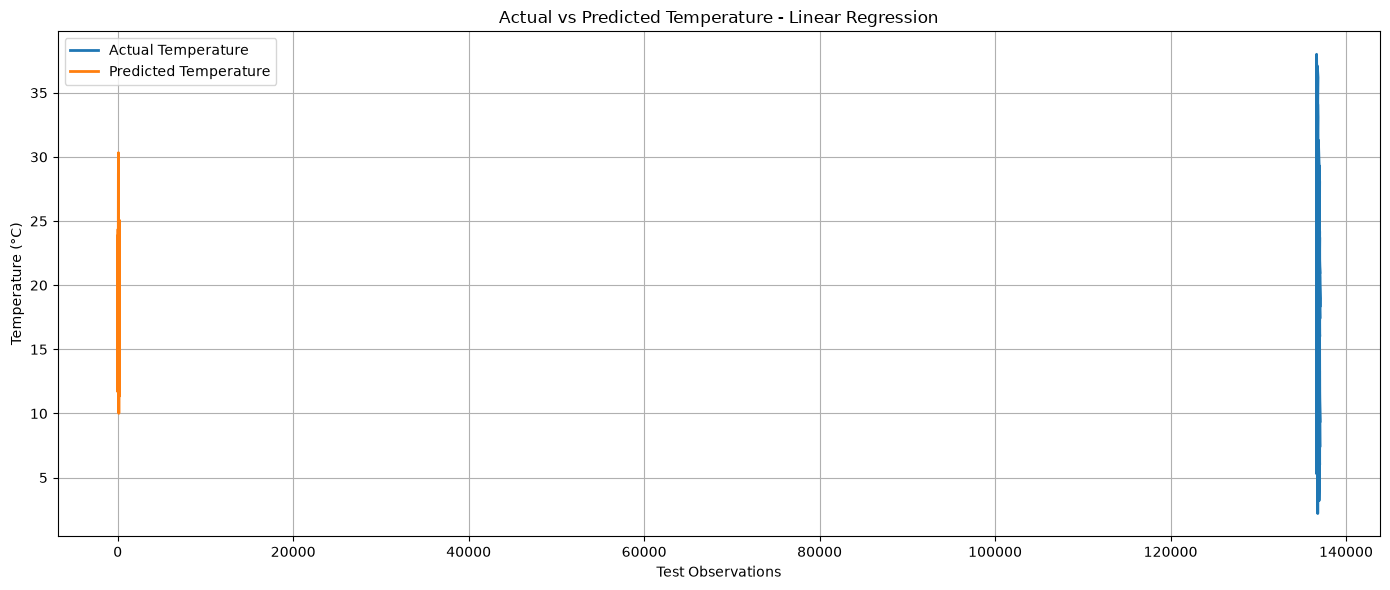

In [50]:
plt.figure(figsize=(14, 6))

plt.plot(
    y_test.iloc[:200],
    label="Actual Temperature",
    linewidth=2
)

plt.plot(
    y_pred[:200],
    label="Predicted Temperature",
    linewidth=2
)

plt.title("Actual vs Predicted Temperature - Linear Regression")
plt.xlabel("Test Observations")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

**Forecasting with Multiple Models**

In [51]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# Initialize models
dt_model = DecisionTreeRegressor(
    max_depth=15,
    random_state=42
)

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

xgb_model = XGBRegressor(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42
)

# Train models
dt_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)
xgb_model.fit(X_train, y_train)

print("All three forecasting models trained successfully!")

All three forecasting models trained successfully!


In [52]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Store model predictions
models = {
    "Linear Regression": lr_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

results = []

for name, model in models.items():

    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

# Create comparison table
model_comparison = pd.DataFrame(results)

model_comparison = model_comparison.sort_values(
    by="RMSE",
    ascending=True
)

display(model_comparison.round(3))

,Model,MAE,MSE,RMSE,R2 Score
3,XGBoost,2.655,13.416,3.663,0.751
2,Random Forest,3.540,23.498,4.847,0.563
1,Decision Tree,3.730,27.420,5.236,0.490
0,Linear Regression,7.641,84.548,9.195,-0.572


**Ensemble Model**

In [53]:
# Generate predictions
xgb_predictions = xgb_model.predict(X_test)
rf_predictions = rf_model.predict(X_test)

# Weighted ensemble
ensemble_predictions = (
    0.7 * xgb_predictions +
    0.3 * rf_predictions
)

print("Ensemble Model Created Successfully!")

Ensemble Model Created Successfully!


In [54]:
# Calculate ensemble evaluation metrics
ensemble_mae = mean_absolute_error(y_test, ensemble_predictions)
ensemble_mse = mean_squared_error(y_test, ensemble_predictions)
ensemble_rmse = np.sqrt(ensemble_mse)
ensemble_r2 = r2_score(y_test, ensemble_predictions)

# Display results
print("Ensemble Model Performance")
print("--------------------------")
print("MAE:", round(ensemble_mae, 3))
print("MSE:", round(ensemble_mse, 3))
print("RMSE:", round(ensemble_rmse, 3))
print("R2 Score:", round(ensemble_r2, 3))

Ensemble Model Performance
--------------------------
MAE: 2.788
MSE: 14.797
RMSE: 3.847
R2 Score: 0.725


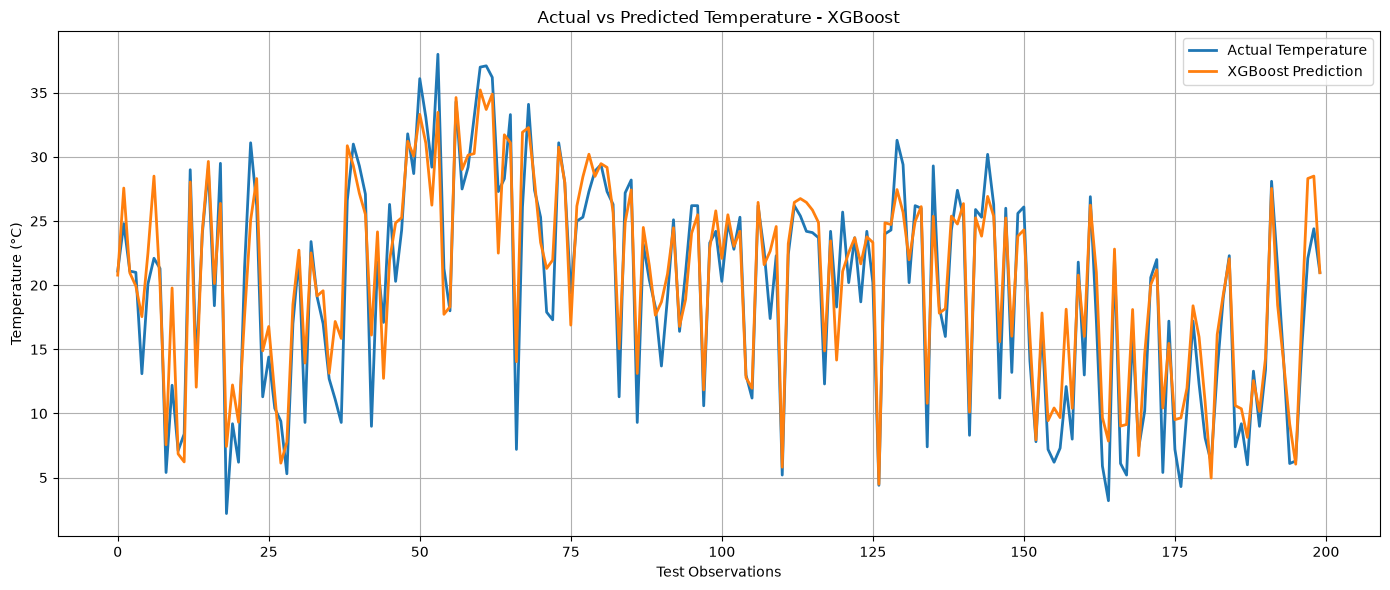

In [55]:
plt.figure(figsize=(14, 6))

plt.plot(
    y_test.iloc[:200].values,
    label="Actual Temperature",
    linewidth=2
)

plt.plot(
    xgb_predictions[:200],
    label="XGBoost Prediction",
    linewidth=2
)

plt.title("Actual vs Predicted Temperature - XGBoost")
plt.xlabel("Test Observations")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [68]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Training predictions
train_predictions = xgb_model.predict(X_train)

# Testing predictions
test_predictions = xgb_model.predict(X_test)

# Calculate metrics
results = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "MAE": [
        mean_absolute_error(y_train, train_predictions),
        mean_absolute_error(y_test, test_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_train, train_predictions)),
        np.sqrt(mean_squared_error(y_test, test_predictions))
    ],
    "R2 Score": [
        r2_score(y_train, train_predictions),
        r2_score(y_test, test_predictions)
    ]
})

display(results.round(4))

,Dataset,MAE,RMSE,R2 Score
0,Training,2.0628,2.7946,0.9168
1,Testing,2.6552,3.6628,0.7505


In [69]:
import numpy as np
import pandas as pd

# Create cyclical time features
df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)
df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)

df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

df["day_sin"] = np.sin(2 * np.pi * df["day_of_year"] / 365.25)
df["day_cos"] = np.cos(2 * np.pi * df["day_of_year"] / 365.25)

# Select features
improved_features = [
    "year",
    "latitude",
    "longitude",
    "month_sin",
    "month_cos",
    "hour_sin",
    "hour_cos",
    "day_sin",
    "day_cos"
]

X_improved = df[improved_features]
y_improved = df["temperature_celsius"]

# Maintain chronological 80:20 split
X_train_new = X_improved.iloc[:split_index]
X_test_new = X_improved.iloc[split_index:]

y_train_new = y_improved.iloc[:split_index]
y_test_new = y_improved.iloc[split_index:]

print("Training shape:", X_train_new.shape)
print("Testing shape:", X_test_new.shape)

Training shape: (136741, 9)
Testing shape: (34186, 9)


In [ ]:
from xgboost import XGBRegressor

# Initialize improved XGBoost model
improved_xgb = XGBRegressor(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.03,
    subsample=0.85,
    colsample_bytree=0.85,
    min_child_weight=3,
    reg_alpha=0.1,
    reg_lambda=5,
    random_state=42,
    n_jobs=-1,
    objective="reg:squarederror"
)

# Train model
improved_xgb.fit(X_train_new, y_train_new)

# Generate predictions
train_predictions_new = improved_xgb.predict(X_train_new)
test_predictions_new = improved_xgb.predict(X_test_new)

print("Improved XGBoost model trained successfully!")

Improved XGBoost model trained successfully!


In [71]:

# Calculate training and testing metrics
improved_results = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "MAE": [
        mean_absolute_error(y_train_new, train_predictions_new),
        mean_absolute_error(y_test_new, test_predictions_new)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_train_new, train_predictions_new)),
        np.sqrt(mean_squared_error(y_test_new, test_predictions_new))
    ],
    "R2 Score": [
        r2_score(y_train_new, train_predictions_new),
        r2_score(y_test_new, test_predictions_new)
    ]
})

display(improved_results.round(4))

,Dataset,MAE,RMSE,R2 Score
0,Training,2.1333,2.8841,0.9113
1,Testing,2.4062,3.2484,0.8038


In [56]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(
    improved_xgb,
    "../models/improved_xgboost_weather_model.pkl"
)

joblib.dump(
    improved_features,
    "../models/improved_weather_features.pkl"
)

print("Improved XGBoost model saved successfully!")

Improved XGBoost model saved successfully!


**Unique Analyses**

In [57]:
# Extract year and month
df["year"] = df["last_updated"].dt.year
df["month"] = df["last_updated"].dt.month

# Calculate monthly average temperature for each location
monthly_by_location = (
    df.groupby(["location_name", "year", "month"])["temperature_celsius"]
    .mean()
    .reset_index()
)

# Calculate average monthly temperature across locations
monthly_temperature = (
    monthly_by_location.groupby(["year", "month"])["temperature_celsius"]
    .mean()
    .reset_index()
)

# Create date column
monthly_temperature["date"] = pd.to_datetime(
    monthly_temperature[["year", "month"]].assign(day=1)
)

# Sort data chronologically
monthly_temperature = monthly_temperature.sort_values("date")

# Display results
display(monthly_temperature.head(15))

,year,month,temperature_celsius,date
0,2024,5,25.033040,2024-05-01
1,2024,6,26.104598,2024-06-01
2,2024,7,27.036899,2024-07-01
3,2024,8,26.794164,2024-08-01
4,2024,9,25.126457,2024-09-01
5,2024,10,22.325377,2024-10-01
6,2024,11,19.432904,2024-11-01
7,2024,12,17.751894,2024-12-01
8,2025,1,17.410134,2025-01-01
9,2025,2,17.427221,2025-02-01


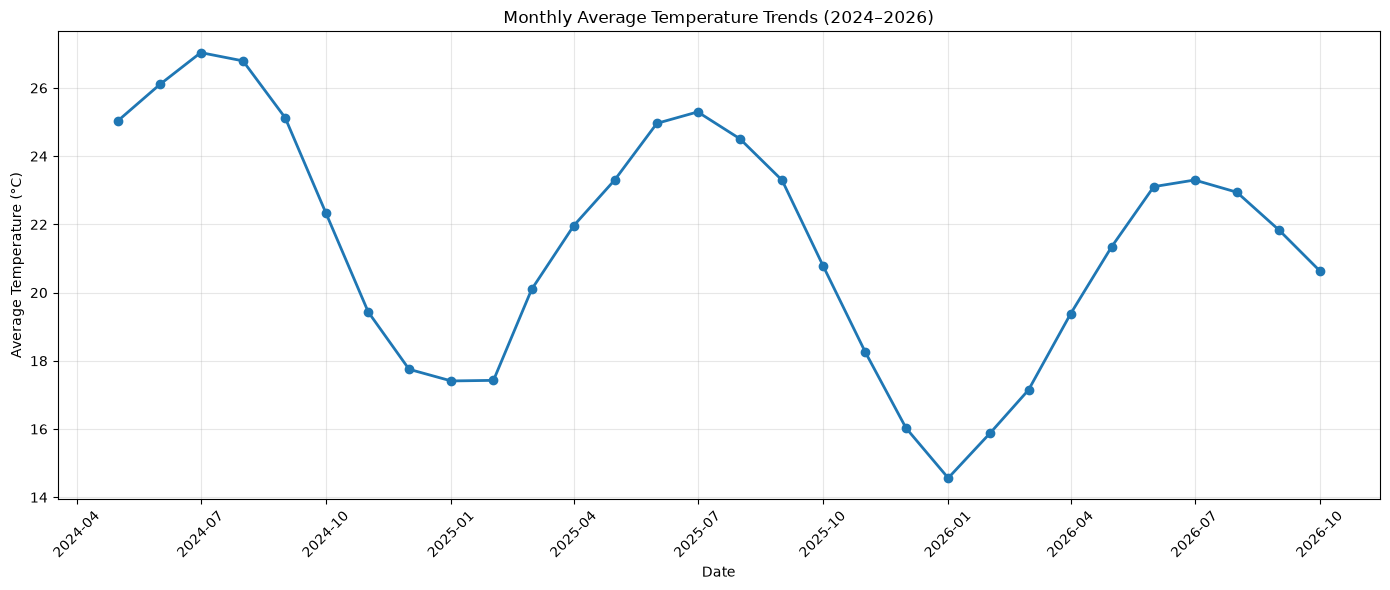

In [58]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_temperature["date"],
    monthly_temperature["temperature_celsius"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Average Temperature Trends (2024–2026)")
plt.xlabel("Date")
plt.ylabel("Average Temperature (°C)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [59]:
# Calculate yearly average temperature across locations
yearly_temperature = (
    df.groupby(["location_name", "year"])["temperature_celsius"]
    .mean()
    .reset_index()
)

yearly_temperature = (
    yearly_temperature.groupby("year")["temperature_celsius"]
    .mean()
    .reset_index()
)

yearly_temperature.columns = ["Year", "Average Temperature (°C)"]

display(yearly_temperature.round(2))

,Year,Average Temperature (°C)
0,2024,23.99
1,2025,20.94
2,2026,20.34


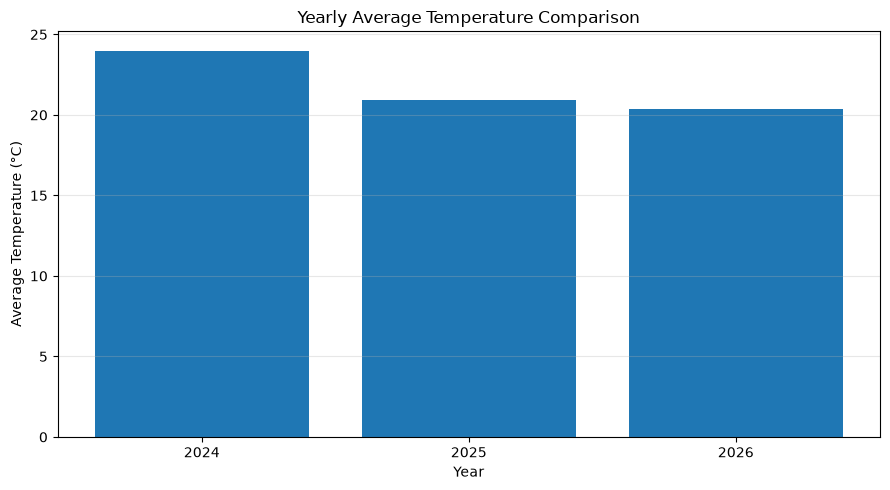

In [60]:
plt.figure(figsize=(9, 5))

plt.bar(
    yearly_temperature["Year"].astype(str),
    yearly_temperature["Average Temperature (°C)"]
)

plt.title("Yearly Average Temperature Comparison")
plt.xlabel("Year")
plt.ylabel("Average Temperature (°C)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

,Feature,Importance
5,latitude,0.3242
1,month,0.2975
4,day_of_year,0.1925
3,hour,0.0827
6,longitude,0.0655
0,year,0.0350
2,day,0.0026


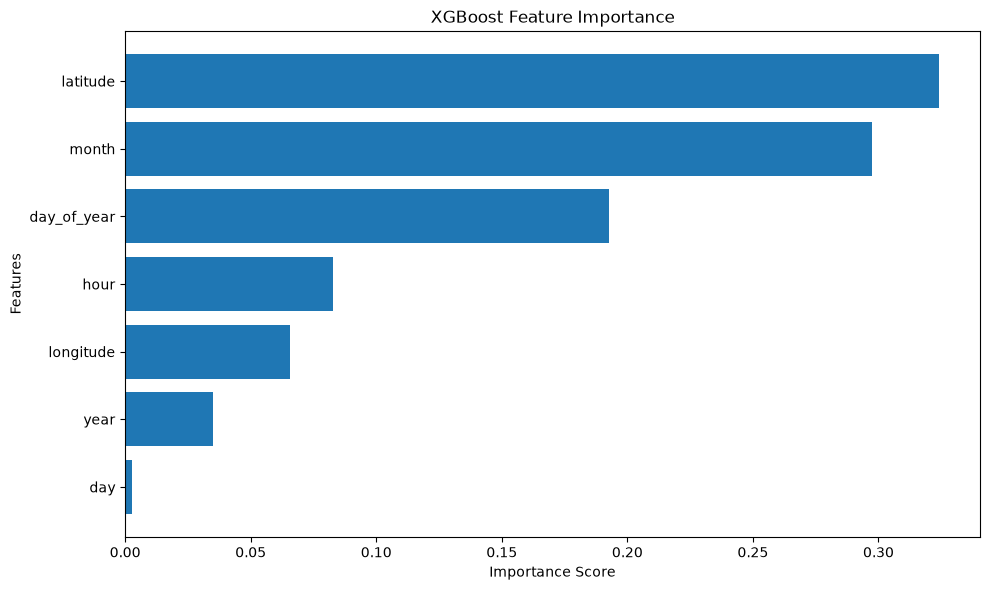

In [61]:

# Get feature importance from XGBoost
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": xgb_model.feature_importances_
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

display(feature_importance.round(4))

# Visualize feature importance
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.title("XGBoost Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

,Feature,Importance
5,latitude,3.7684
6,longitude,0.9065
3,hour,0.7909
4,day_of_year,0.7356
1,month,0.0016
2,day,0.0001
0,year,0.0000


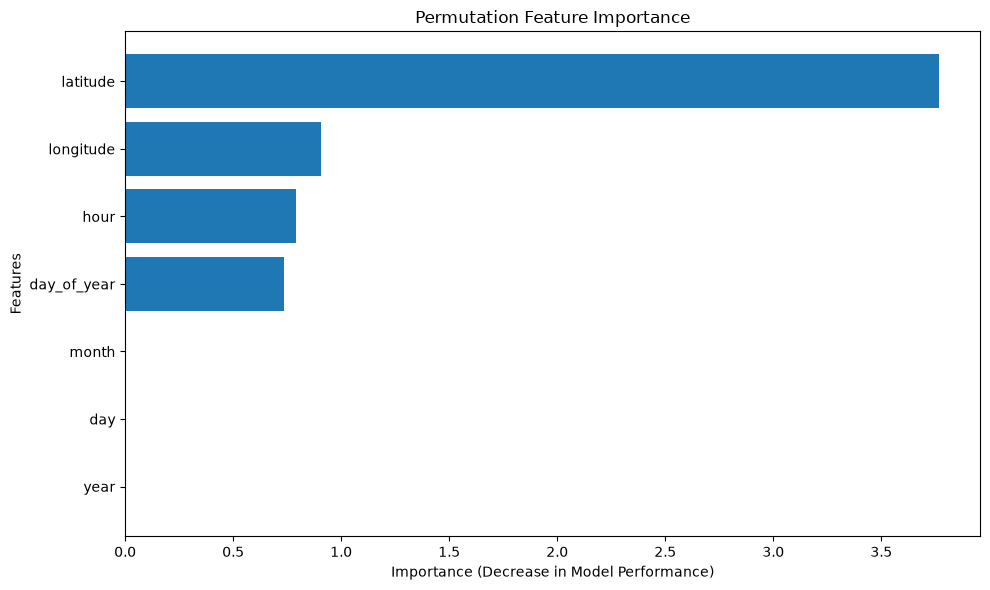

In [62]:
from sklearn.inspection import permutation_importance

# Calculate permutation importance
permutation_result = permutation_importance(
    xgb_model,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

# Create results DataFrame
permutation_importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": permutation_result.importances_mean
})

# Sort by importance
permutation_importance_df = permutation_importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(permutation_importance_df.round(4))

# Visualize results
plt.figure(figsize=(10, 6))

plt.barh(
    permutation_importance_df["Feature"],
    permutation_importance_df["Importance"]
)

plt.title("Permutation Feature Importance")
plt.xlabel("Importance (Decrease in Model Performance)")
plt.ylabel("Features")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

**Spatial Analysis**

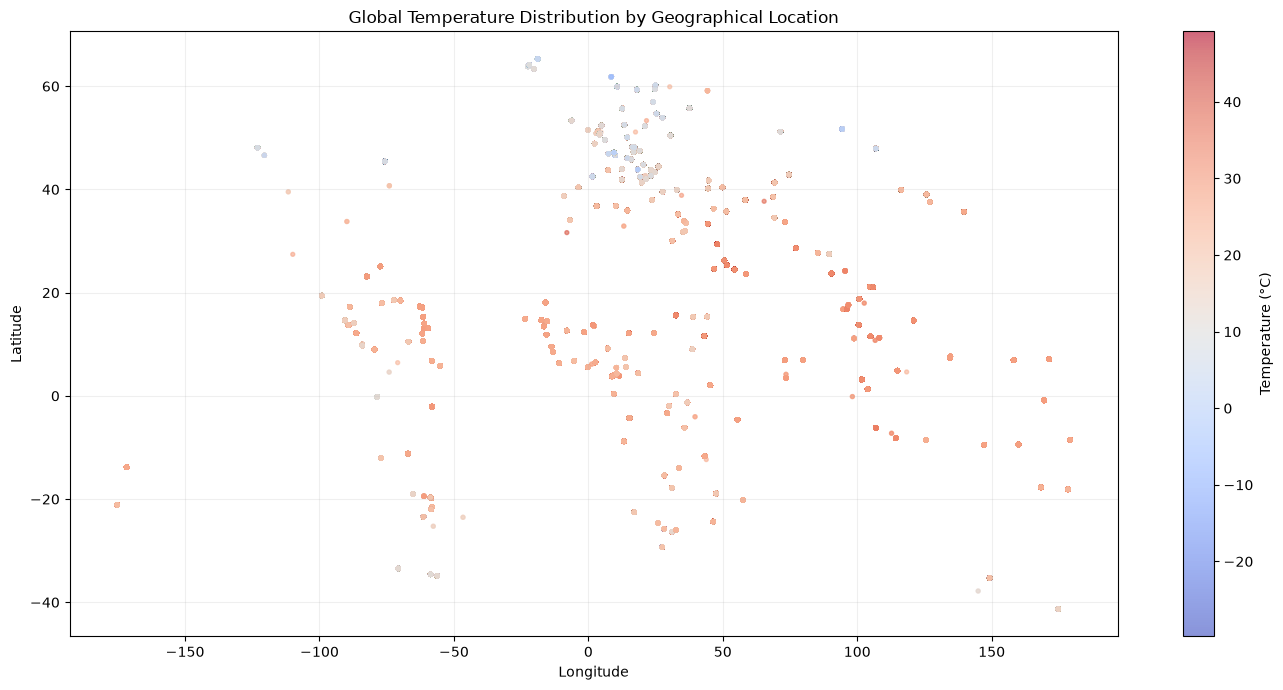

In [63]:
plt.figure(figsize=(14, 7))

scatter = plt.scatter(
    df["longitude"],
    df["latitude"],
    c=df["temperature_celsius"],
    cmap="coolwarm",
    s=8,
    alpha=0.6
)

plt.colorbar(scatter, label="Temperature (°C)")
plt.title("Global Temperature Distribution by Geographical Location")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

**Geographical Patterns**

In [65]:
# Calculate temperature statistics for each country
country_temperature = (
    df.groupby("country")["temperature_celsius"]
    .agg(["mean", "min", "max", "count"])
    .reset_index()
)

country_temperature.columns = [
    "Country",
    "Average Temperature",
    "Minimum Temperature",
    "Maximum Temperature",
    "Record Count"
]

# Sort countries by average temperature
country_temperature = country_temperature.sort_values(
    by="Average Temperature",
    ascending=False
)

# Display 10 countries with highest average temperatures
print("Top 10 Countries by Average Temperature:")
display(country_temperature.head(10).round(2))

# Display 10 countries with lowest average temperatures
print("Top 10 Countries by Lowest Average Temperature:")
display(
    country_temperature.tail(10)
    .sort_values("Average Temperature")
    .round(2)
)

Top 10 Countries by Average Temperature:


,Country,Average Temperature,Minimum Temperature,Maximum Temperature,Record Count
158,Saudi Arabien,45.00,45.0,45.0,1
114,Marrocos,40.30,40.3,40.3,1
189,Turkménistan,37.80,37.8,37.8,1
208,Турция,34.00,34.0,34.0,1
147,Qatar,32.97,15.2,46.3,876
194,United Arab Emirates,32.53,18.0,46.4,878
29,Cambodia,32.09,22.6,39.9,877
136,Oman,31.80,18.0,46.3,878
94,Kuwait,31.64,7.3,49.2,877
48,Djibouti,31.49,23.3,47.1,875


Top 10 Countries by Lowest Average Temperature:


,Country,Average Temperature,Minimum Temperature,Maximum Temperature,Record Count
76,Iceland,5.72,-25.4,18.1,876
122,Mongolia,6.06,-29.8,34.3,877
31,Canada,6.62,-25.0,29.2,876
135,Norway,8.36,-19.6,26.2,911
3,Andorra,9.02,-14.4,28.9,878
196,United States of America,9.43,-2.8,26.1,874
60,Finland,9.48,-23.9,29.1,878
149,Russia,9.60,-25.8,32.2,932
56,Estonia,9.80,-17.6,32.3,876
104,Lithuania,10.09,-23.9,31.2,877


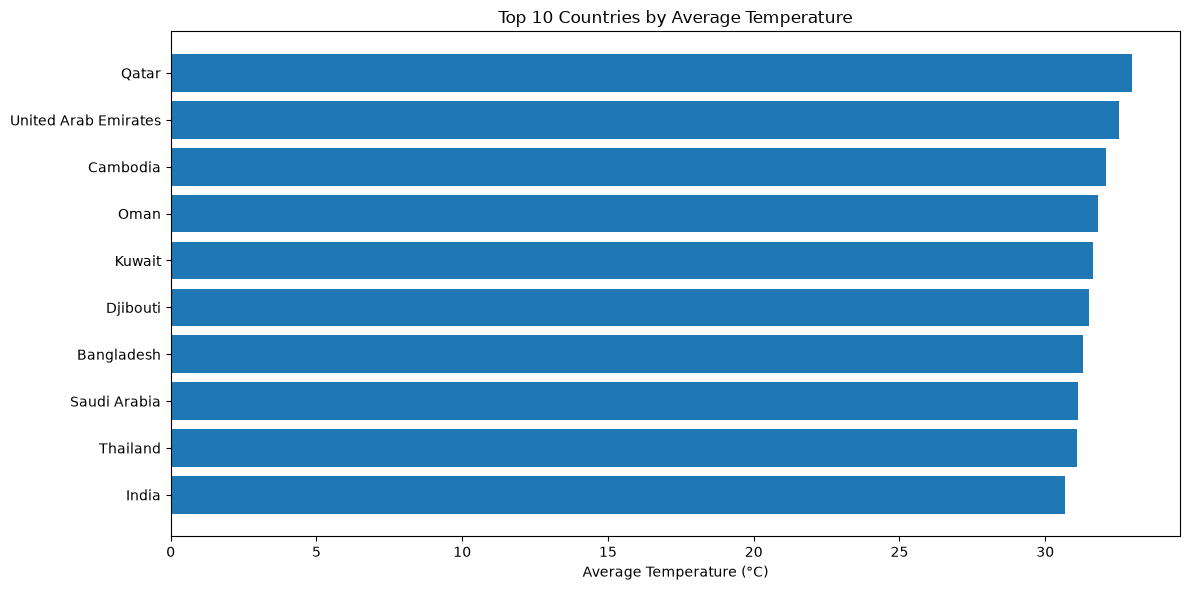

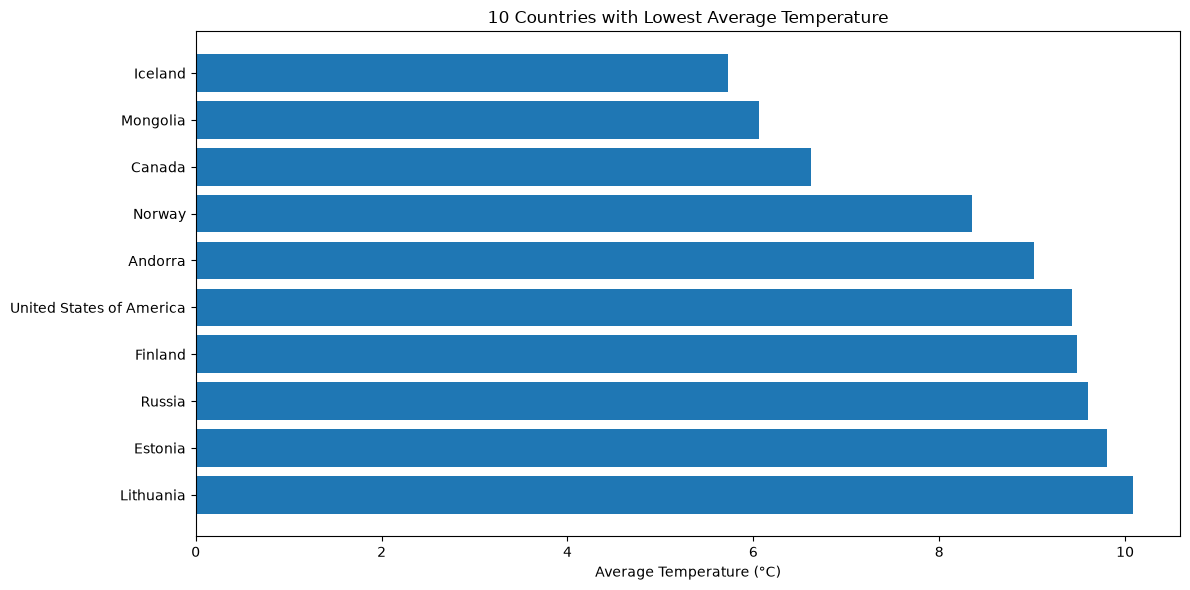

In [66]:
import matplotlib.pyplot as plt

# Filter countries with sufficient records
reliable_countries = country_temperature[
    country_temperature["Record Count"] >= 100
]

# Select highest and lowest 10 countries
top_countries = reliable_countries.nlargest(
    10, "Average Temperature"
)

bottom_countries = reliable_countries.nsmallest(
    10, "Average Temperature"
)

# Plot highest temperature countries
plt.figure(figsize=(12, 6))

plt.barh(
    top_countries["Country"],
    top_countries["Average Temperature"]
)

plt.title("Top 10 Countries by Average Temperature")
plt.xlabel("Average Temperature (°C)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Plot lowest temperature countries
plt.figure(figsize=(12, 6))

plt.barh(
    bottom_countries["Country"],
    bottom_countries["Average Temperature"]
)

plt.title("10 Countries with Lowest Average Temperature")
plt.xlabel("Average Temperature (°C)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


#  Project Conclusion

This project focused on analyzing global weather data and developing machine learning models to predict temperature.

The dataset was cleaned and preprocessed by handling duplicate records, checking missing values, identifying unusual temperature readings, and applying feature scaling.

Exploratory Data Analysis (EDA) was performed to understand temperature distributions, weather conditions, and time-based patterns.

Isolation Forest was used for anomaly detection. Multiple machine learning models, including Linear Regression, Decision Tree, Random Forest, and XGBoost, were trained and evaluated.


Additional analyses included monthly and yearly temperature trends, feature importance, spatial temperature distribution, and geographical comparisons across countries.

**Limitations:**
- The dataset does not contain air-quality or precipitation measurements.
- The available date range is limited for long-term climate analysis.
- Country-level comparisons may be affected by inconsistent country names and unequal data coverage.

**Final Outcome:**

The project demonstrates how data preprocessing, exploratory analysis, anomaly detection, machine learning, and geographical analysis can be combined to study global weather patterns and predict temperature.
